# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
# Ejemplo visual de la diferencia
print("Valores únicos en 'sex' después de LabelEncoder:", data['sex_label'].unique())
# Salida: [1, 0] (Hombre=1, Mujer=0)

# Ver columnas creadas por OneHotEncoder para 'embarked'
print("Nuevas columnas de Embarked:", [col for col in data.columns if 'embarked_' in col])
# Salida: ['embarked_C', 'embarked_Q', 'embarked_S']

Valores únicos en 'sex' después de LabelEncoder: [1 0]
Nuevas columnas de Embarked: ['embarked_C', 'embarked_Q', 'embarked_S']


### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

/tmp/ipykernel_15292/225980921.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sex', data=data, ax=axes[0], palette='pastel')
/tmp/ipykernel_15292/225980921.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sex_label', data=data, ax=axes[1], palette='pastel')


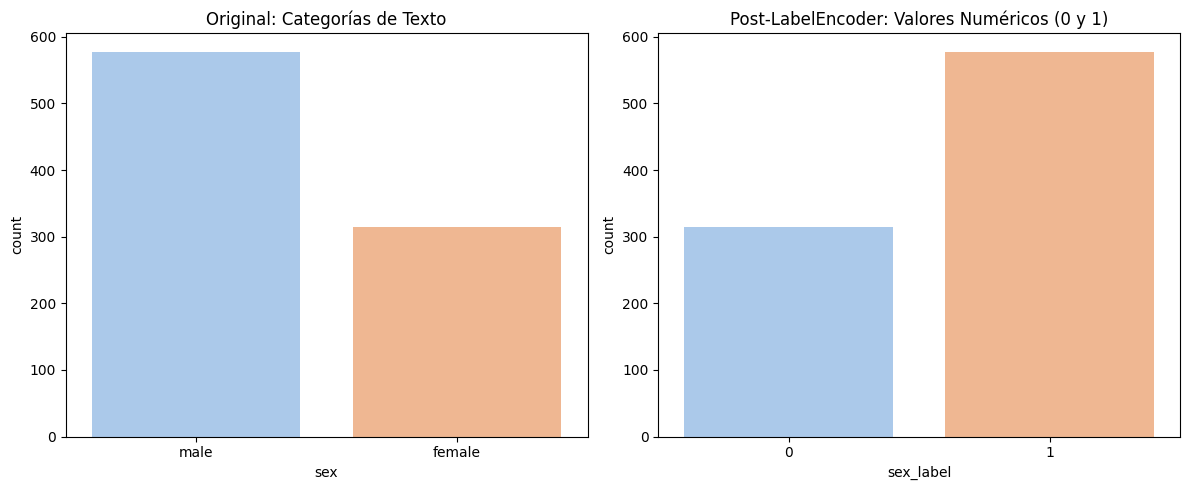

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Antes de la codificación
sns.countplot(x='sex', data=data, ax=axes[0], palette='pastel')
axes[0].set_title('Original: Categorías de Texto')

# Después de LabelEncoder
sns.countplot(x='sex_label', data=data, ax=axes[1], palette='pastel')
axes[1].set_title('Post-LabelEncoder: Valores Numéricos (0 y 1)')

plt.tight_layout()
plt.show()

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [10]:
# Codificación One-Hot para 'class'
class_dummies = pd.get_dummies(data['class'], prefix='class')
data = pd.concat([data, class_dummies], axis=1)

print(data[['class', 'class_First', 'class_Second', 'class_Third']].head())

   class  class_First  class_Second  class_Third
0  Third        False         False         True
1  First         True         False        False
2  Third        False         False         True
3  First         True         False        False
4  Third        False         False         True


### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [11]:
Usaría una combinación: OneHotEncoder para la mayoría de las variables si tengo suficiente memoria, para asegurar que el modelo no asuma relaciones numéricas inexistentes entre categorías.

SyntaxError: invalid syntax (3284552076.py, line 1)